<a href="https://colab.research.google.com/github/I-r-s-h-a-d/food-grocery-intelligence/blob/main/instacard.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Updated path to point to the file in the local Colab directory
DATA_PATH = "/content/food_grocery_100k.csv"
df = pd.read_csv(DATA_PATH)


In [ ]:
# 1. Parse timestamps & engineer basic time/SLA columns
df["order_timestamp"] = pd.to_datetime(df["order_timestamp"])
df["order_hour"] = df["order_timestamp"].dt.hour
df["order_day"] = df["order_timestamp"].dt.day_name()
df["delay_mins"] = df["actual_delivery_mins"] - df["promised_eta_mins"]

print("Shape:", df.shape)
print("Missing values:\n", df.isna().sum()[df.isna().sum() > 0])
print("Duplicate rows:", df.duplicated().sum())



Shape: (100000, 19)
Missing values:
 Series([], dtype: int64)
Duplicate rows: 0


In [ ]:


# 2. Numeric summary
num_cols = [
    "quantity",
    "unit_price",
    "discount_amount",
    "line_total",
    "promised_eta_mins",
    "actual_delivery_mins",
    "delay_mins",
]
print("\nNumeric Summary:")
print(df[num_cols].describe().T[["count", "mean", "50%", "std", "min", "max"]])




Numeric Summary:
                         count        mean      50%         std    min  \
quantity              100000.0    1.770870    1.000    1.056192   1.00   
unit_price            100000.0  431.944595  430.725  241.155144  15.02   
discount_amount       100000.0   19.964388   13.770   19.995719   0.00   
line_total            100000.0  745.690125  571.055  674.528693   0.00   
promised_eta_mins     100000.0   29.516260   30.000    8.672222  15.00   
actual_delivery_mins  100000.0   31.551900   31.000   11.634604   8.00   
delay_mins            100000.0    2.035640    2.000    7.892003 -32.00   

                          max  
quantity                 5.00  
unit_price             850.00  
discount_amount        245.22  
line_total            4239.87  
promised_eta_mins       44.00  
actual_delivery_mins    77.00  
delay_mins              38.00  


In [ ]:


# 3. On-time delivery rate & revenue by city
city_summary = (
    df.groupby("city", as_index=False)
    .agg(
        orders=("order_id", "nunique"),
        line_items=("row_id", "count"),
        total_revenue=("line_total", "sum"),
        on_time_rate=("is_on_time", "mean"),
        avg_delay_mins=("delay_mins", "mean"),
    )
    .sort_values("total_revenue", ascending=False)
)
print("\nCity Summary:")
print(city_summary.to_string(index=False))


City Summary:
     city  orders  line_items  total_revenue  on_time_rate  avg_delay_mins
Bengaluru   19024       23968    17801567.34      0.426903        2.065963
   Mumbai   16531       20088    15050901.61      0.425428        2.025986
Delhi NCR   15088       17952    13341110.60      0.431930        2.066455
Hyderabad   12104       13931    10498825.88      0.430838        2.008901
     Pune   10669       12024     8958542.32      0.421906        2.062625
  Chennai   10758       12037     8918064.79      0.428180        1.949406


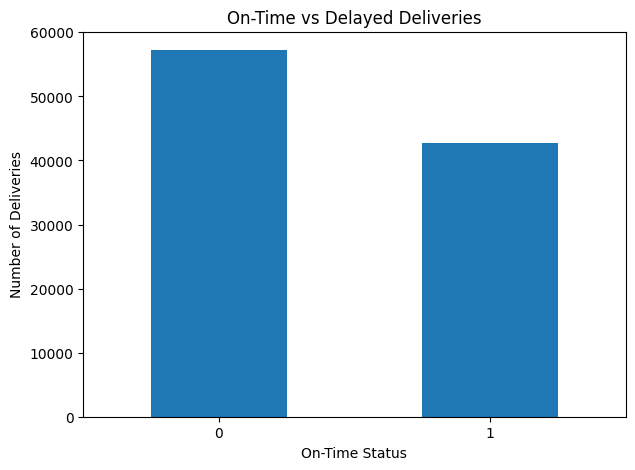

In [ ]:
delivery_status = df.groupby("is_on_time").size()

plt.figure(figsize=(7, 5))
delivery_status.plot(kind="bar")
plt.title("On-Time vs Delayed Deliveries")
plt.xlabel("On-Time Status")
plt.ylabel("Number of Deliveries")
plt.xticks(rotation=0)
plt.show()

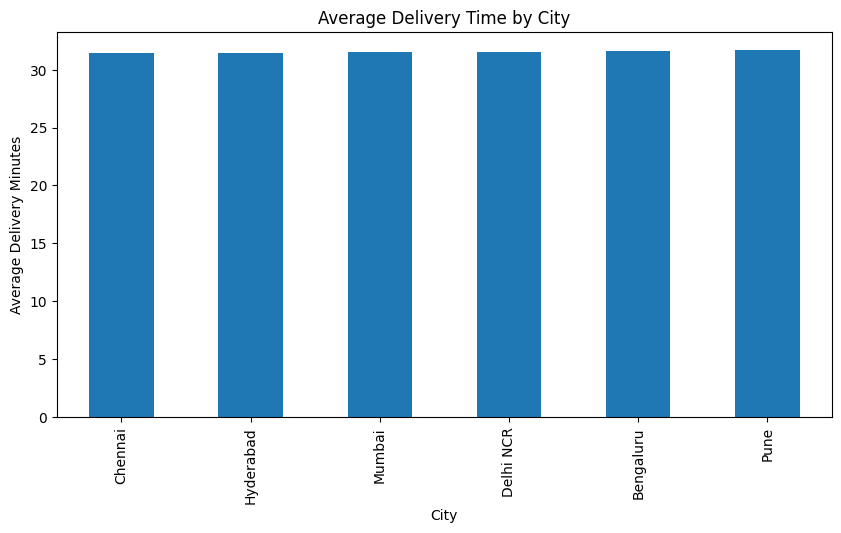

In [ ]:
city_delivery = df.groupby("city")[
    "actual_delivery_mins"
].mean().sort_values()

city_delivery.plot(kind="bar", figsize=(10, 5))
plt.title("Average Delivery Time by City")
plt.xlabel("City")
plt.ylabel("Average Delivery Minutes")
plt.show()

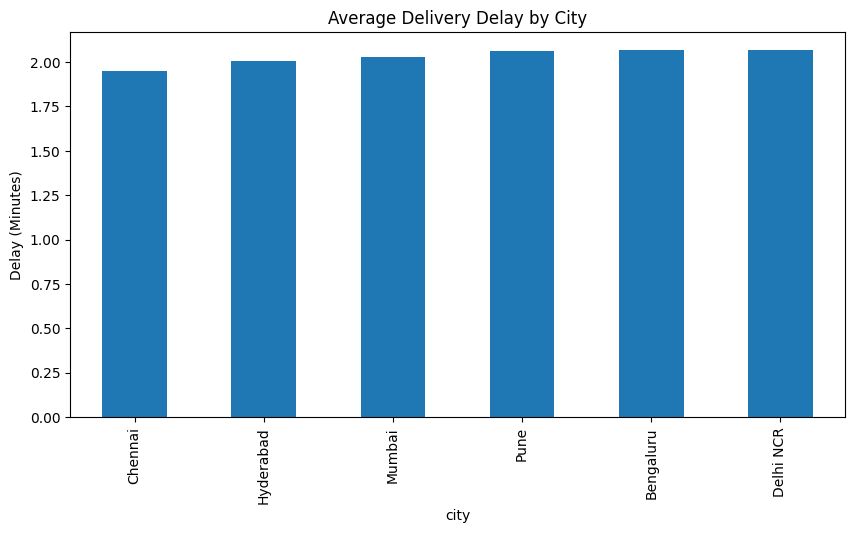

In [ ]:
city_delay = df.groupby("city")["delay_mins"].mean().sort_values()

city_delay.plot(kind="bar", figsize=(10, 5))
plt.title("Average Delivery Delay by City")
plt.ylabel("Delay (Minutes)")
plt.show()

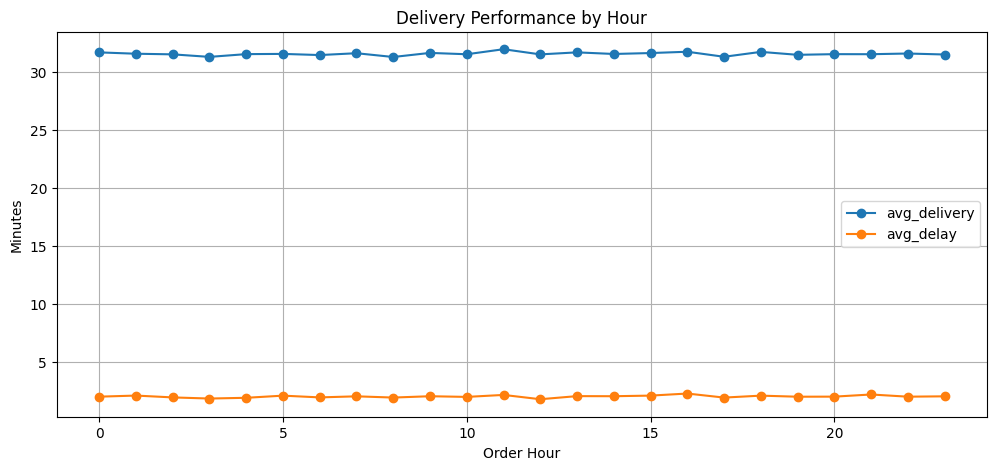

In [ ]:
hourly_delivery = df.groupby("order_hour").agg(
    avg_delivery=("actual_delivery_mins", "mean"),
    avg_delay=("delay_mins", "mean")
)

hourly_delivery.plot(
    kind="line",
    marker="o",
    figsize=(12, 5)
)

plt.title("Delivery Performance by Hour")
plt.xlabel("Order Hour")
plt.ylabel("Minutes")
plt.grid()
plt.show()

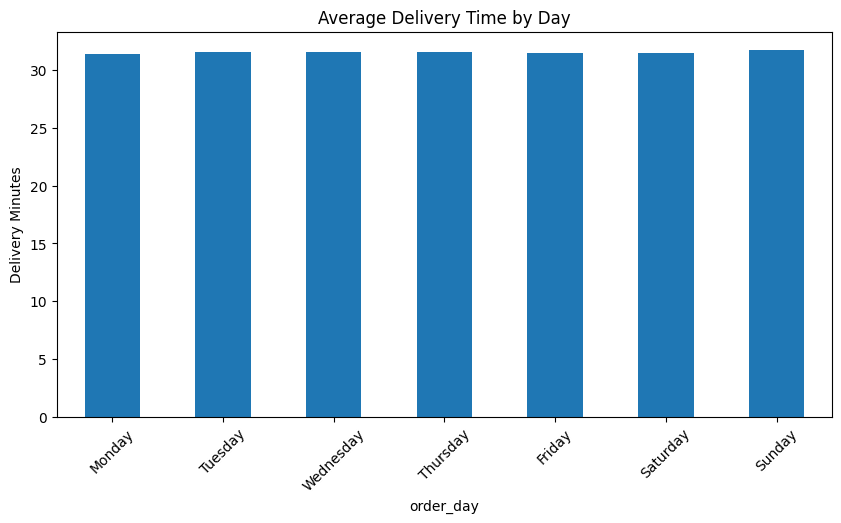

In [ ]:
day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

daily_delivery = df.groupby("order_day")[
    "actual_delivery_mins"
].mean().reindex(day_order)

daily_delivery.plot(kind="bar", figsize=(10, 5))
plt.title("Average Delivery Time by Day")
plt.ylabel("Delivery Minutes")
plt.xticks(rotation=45)
plt.show()

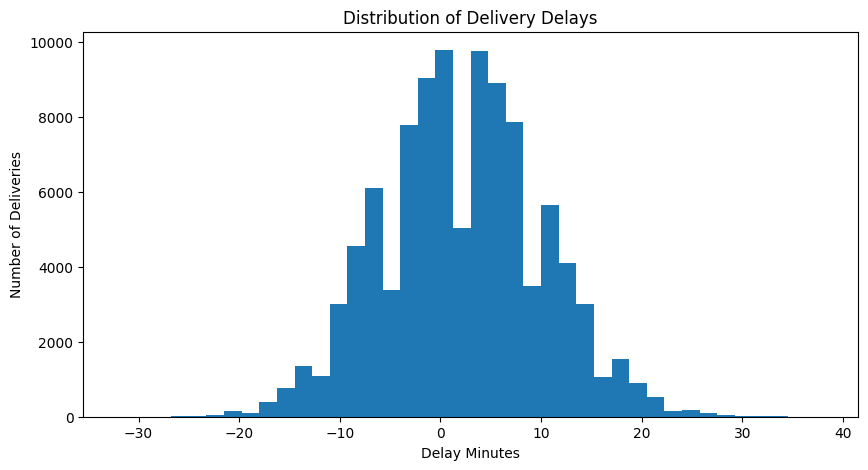

In [ ]:
plt.figure(figsize=(10, 5))

plt.hist(df["delay_mins"].dropna(), bins=40)

plt.title("Distribution of Delivery Delays")
plt.xlabel("Delay Minutes")
plt.ylabel("Number of Deliveries")
plt.show()

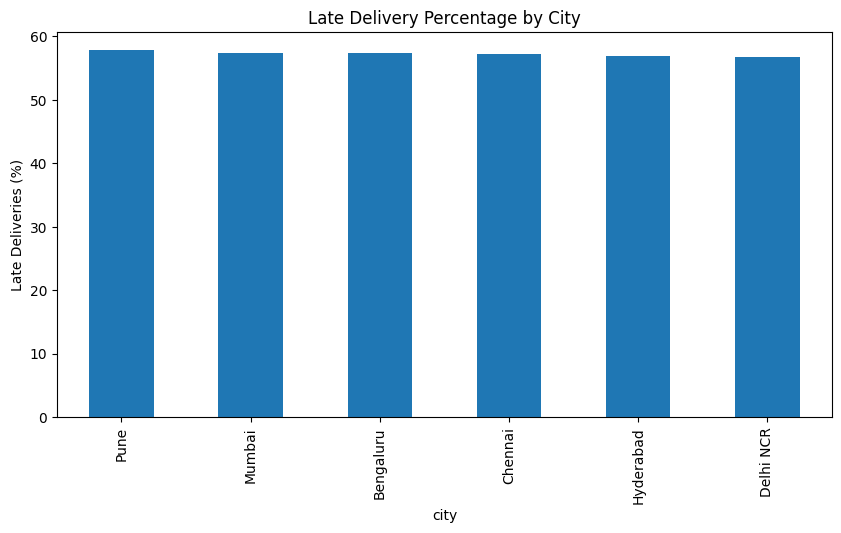

In [ ]:
late_delivery = (
    df.groupby("city")["is_on_time"]
    .apply(lambda x: (x == 0).mean() * 100)
    .sort_values(ascending=False)
)

late_delivery.plot(kind="bar", figsize=(10, 5))

plt.title("Late Delivery Percentage by City")
plt.ylabel("Late Deliveries (%)")
plt.show()

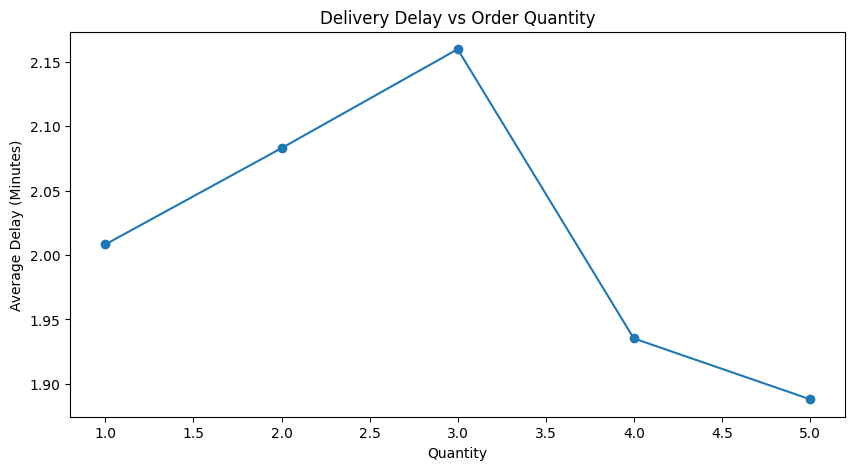

In [ ]:
quantity_delay = df.groupby("quantity")["delay_mins"].mean()

quantity_delay.plot(
    kind="line",
    marker="o",
    figsize=(10, 5)
)

plt.title("Delivery Delay vs Order Quantity")
plt.xlabel("Quantity")
plt.ylabel("Average Delay (Minutes)")
plt.show()

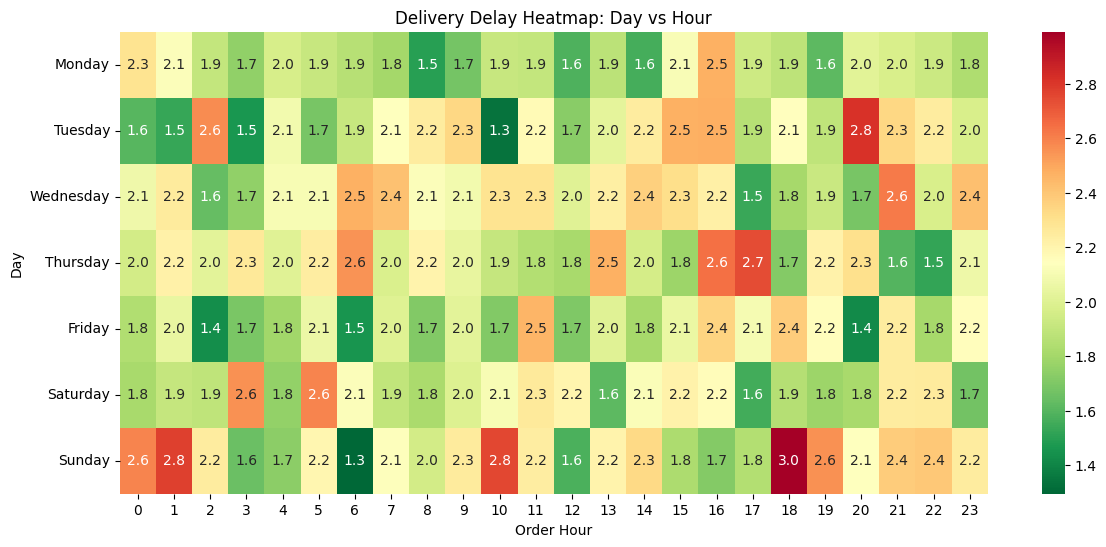

In [ ]:
import seaborn as sns

delivery_heatmap = df.pivot_table(
    index="order_day",
    columns="order_hour",
    values="delay_mins",
    aggfunc="mean"
).reindex(day_order)

plt.figure(figsize=(14, 6))

sns.heatmap(
    delivery_heatmap,
    cmap="RdYlGn_r",
    annot=True,
    fmt=".1f"
)

plt.title("Delivery Delay Heatmap: Day vs Hour")
plt.xlabel("Order Hour")
plt.ylabel("Day")
plt.show()


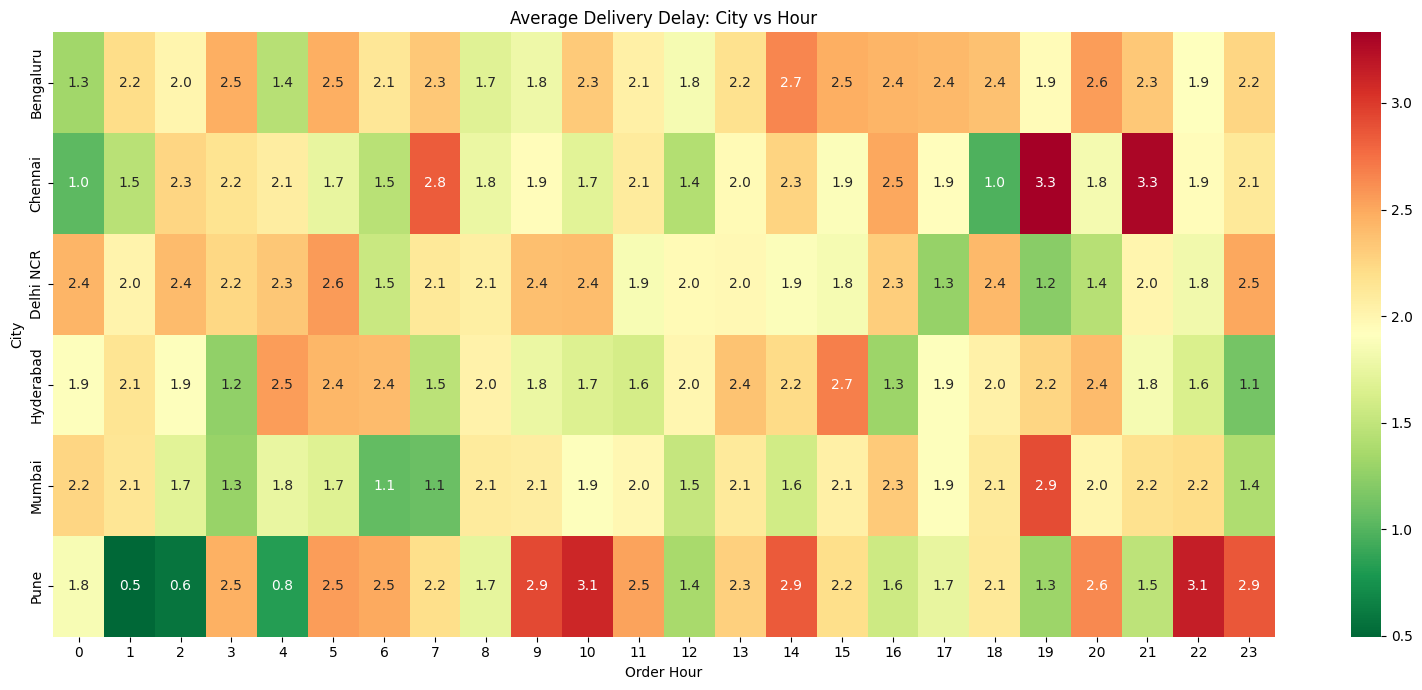

In [ ]:

import seaborn as sns
import matplotlib.pyplot as plt

# One record per order to avoid counting multiple items
orders = df.drop_duplicates(subset="order_id").copy()

city_hour_delay = orders.pivot_table(
    index="city",
    columns="order_hour",
    values="delay_mins",
    aggfunc="mean"
)

plt.figure(figsize=(16, 7))

sns.heatmap(
    city_hour_delay,
    cmap="RdYlGn_r",
    annot=True,
    fmt=".1f"
)

plt.title("Average Delivery Delay: City vs Hour")
plt.xlabel("Order Hour")
plt.ylabel("City")
plt.tight_layout()
plt.show()


In [ ]:

worst_slots = (
    orders.groupby(["city", "order_hour"])
    .agg(
        avg_delay=("delay_mins", "mean"),
        total_orders=("order_id", "count"),
        late_orders=("is_on_time", lambda x: (~x.astype(bool)).sum())
    )
    .reset_index()
)

worst_slots = worst_slots.sort_values(
    "avg_delay", ascending=False
)

print("10 Worst Delivery Time Slots")
print(worst_slots.head(10).to_string(index=False))


10 Worst Delivery Time Slots
     city  order_hour  avg_delay  total_orders  late_orders
  Chennai          19   3.331522           184          118
  Chennai          21   3.296117           206          128
     Pune          22   3.147679           237          160
     Pune          10   3.104072           221          139
     Pune           9   2.927350           234          143
   Mumbai          19   2.919771           349          218
     Pune          23   2.864322           199          124
     Pune          14   2.851406           249          156
  Chennai           7   2.838863           211          128
Hyderabad          15   2.687259           259          153


In [ ]:

city_performance = orders.groupby("city").agg(
    total_orders=("order_id", "nunique"),
    avg_delivery=("actual_delivery_mins", "mean"),
    avg_promised_eta=("promised_eta_mins", "mean"),
    avg_delay=("delay_mins", "mean"),
    on_time_rate=("is_on_time", "mean")
).reset_index()

city_performance["on_time_rate"] *= 100

city_performance = city_performance.sort_values(
    "on_time_rate"
)

print(city_performance.to_string(index=False))


     city  total_orders  avg_delivery  avg_promised_eta  avg_delay  on_time_rate
     Pune          5236     31.750382         29.688312   2.062070     41.329259
Bengaluru         10325     31.657627         29.509927   2.147700     41.946731
  Chennai          5128     31.369150         29.382995   1.986154     42.648206
   Mumbai          8670     31.434025         29.543137   1.890888     43.206459
Delhi NCR          7800     31.525000         29.491282   2.033718     43.615385
Hyderabad          6069     31.318010         29.361180   1.956830     43.664525


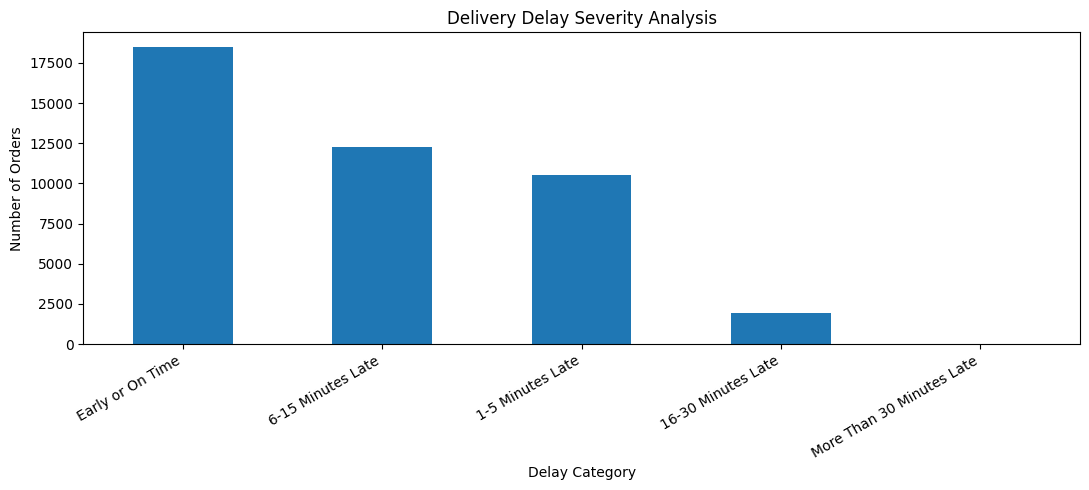

In [ ]:

orders["delay_category"] = pd.cut(
    orders["delay_mins"],
    bins=[-float("inf"), 0, 5, 15, 30, float("inf")],
    labels=[
        "Early or On Time",
        "1-5 Minutes Late",
        "6-15 Minutes Late",
        "16-30 Minutes Late",
        "More Than 30 Minutes Late"
    ]
)

severity = orders["delay_category"].value_counts()

plt.figure(figsize=(11, 5))
severity.plot(kind="bar")

plt.title("Delivery Delay Severity Analysis")
plt.xlabel("Delay Category")
plt.ylabel("Number of Orders")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


In [ ]:

total_orders = orders["order_id"].nunique()

on_time_orders = orders["is_on_time"].astype(bool).sum()

late_orders = total_orders - on_time_orders

print("DELIVERY PERFORMANCE REPORT")
print("-" * 40)

print("Total Orders:", total_orders)

print("On-Time Deliveries:", on_time_orders)

print("Late Deliveries:", late_orders)

print(
    "On-Time Delivery Rate:",
    round(on_time_orders / total_orders * 100, 2), "%"
)

print(
    "Late Delivery Rate:",
    round(late_orders / total_orders * 100, 2), "%"
)

print(
    "Average Delivery Time:",
    round(orders["actual_delivery_mins"].mean(), 2),
    "minutes"
)

print(
    "Average Delay:",
    round(orders["delay_mins"].mean(), 2),
    "minutes"
)


DELIVERY PERFORMANCE REPORT
----------------------------------------
Total Orders: 43228
On-Time Deliveries: 18480
Late Deliveries: 24748
On-Time Delivery Rate: 42.75 %
Late Delivery Rate: 57.25 %
Average Delivery Time: 31.52 minutes
Average Delay: 2.02 minutes


     city  total_orders  on_time_orders  avg_delivery_time  avg_delay  on_time_rate  late_rate
     Pune          5236            2164          31.750382   2.062070     41.329259  58.670741
Bengaluru         10325            4331          31.657627   2.147700     41.946731  58.053269
  Chennai          5128            2187          31.369150   1.986154     42.648206  57.351794
   Mumbai          8670            3746          31.434025   1.890888     43.206459  56.793541
Delhi NCR          7800            3402          31.525000   2.033718     43.615385  56.384615
Hyderabad          6069            2650          31.318010   1.956830     43.664525  56.335475


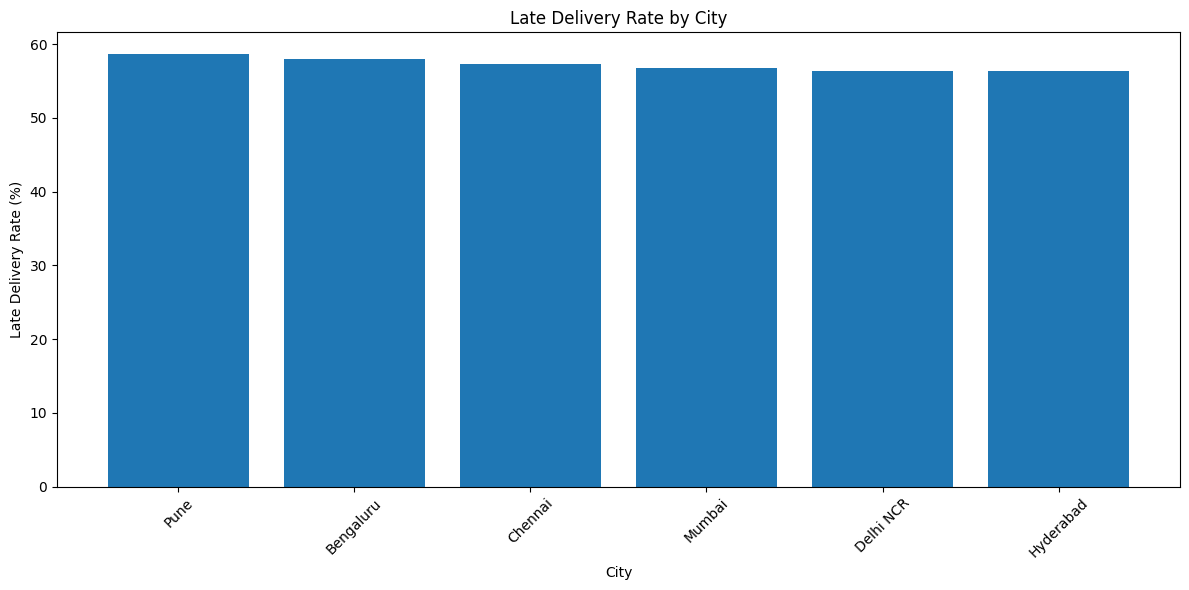

In [ ]:

# CITY-WISE DELIVERY PERFORMANCE

orders = df.drop_duplicates(
    subset="order_id"
).copy()

city_analysis = orders.groupby("city").agg(
    total_orders=("order_id", "nunique"),
    on_time_orders=("is_on_time", "sum"),
    avg_delivery_time=("actual_delivery_mins", "mean"),
    avg_delay=("delay_mins", "mean")
).reset_index()

city_analysis["on_time_rate"] = (
    city_analysis["on_time_orders"] /
    city_analysis["total_orders"] * 100
)

city_analysis["late_rate"] = (
    100 - city_analysis["on_time_rate"]
)

city_analysis = city_analysis.sort_values(
    "late_rate", ascending=False
)

print(city_analysis.to_string(index=False))

# Visualization
plt.figure(figsize=(12, 6))

plt.bar(
    city_analysis["city"],
    city_analysis["late_rate"]
)

plt.title("Late Delivery Rate by City")
plt.xlabel("City")
plt.ylabel("Late Delivery Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



HOURLY DELIVERY ANALYSIS
 order_hour  total_orders  avg_delivery_time  avg_delay  on_time_rate  late_rate
          0          1764          31.591837   1.841837      0.434807  56.519274
          1          1841          31.383487   1.861488      0.440521  55.947854
          2          1852          31.145248   1.865011      0.435205  56.479482
          3          1820          31.575824   1.985714      0.434066  56.593407
          4          1768          31.359729   1.811086      0.434389  56.561086
          5          1677          31.541443   2.245677      0.419201  58.079905
          6          1741          31.319357   1.808156      0.440551  55.944859
          7          1790          31.693296   1.962570      0.433520  56.648045
          8          1781          31.304885   1.900056      0.436272  56.372824
          9          1844          31.585683   2.105206      0.425705  57.429501
         10          1834          31.539258   2.176118      0.416576  58.342421
  

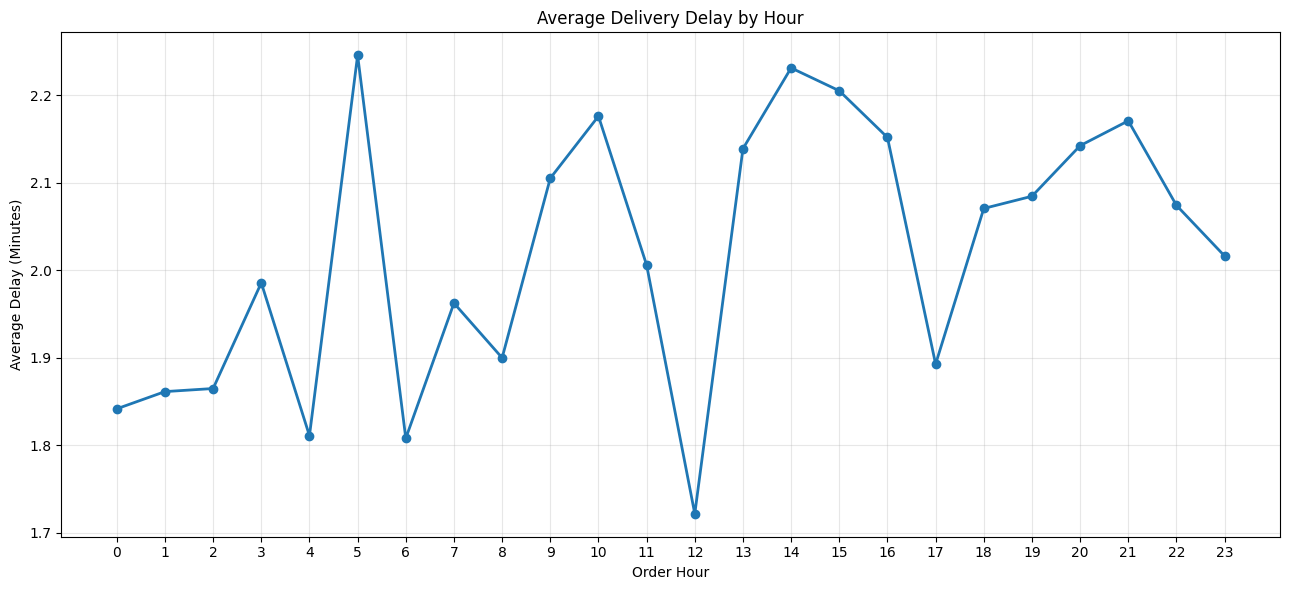

In [ ]:

# PEAK HOUR DELIVERY ANALYSIS

hour_analysis = orders.groupby("order_hour").agg(
    total_orders=("order_id", "nunique"),
    avg_delivery_time=("actual_delivery_mins", "mean"),
    avg_delay=("delay_mins", "mean"),
    on_time_rate=("is_on_time", "mean")
).reset_index()

hour_analysis["late_rate"] = (
    1 - hour_analysis["on_time_rate"]
) * 100

print("\nHOURLY DELIVERY ANALYSIS")
print(hour_analysis.to_string(index=False))

# Visualize average delay
plt.figure(figsize=(13, 6))

plt.plot(
    hour_analysis["order_hour"],
    hour_analysis["avg_delay"],
    marker="o",
    linewidth=2
)

plt.title("Average Delivery Delay by Hour")
plt.xlabel("Order Hour")
plt.ylabel("Average Delay (Minutes)")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


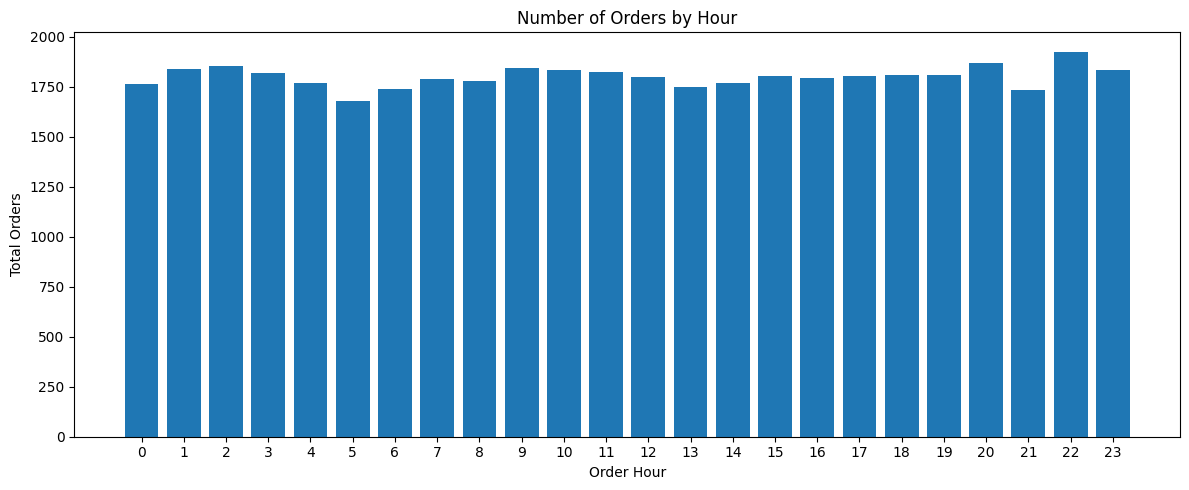

Top 5 Busiest Hours:
    order_hour  total_orders
22          22          1926
20          20          1868
2            2          1852
9            9          1844
1            1          1841


In [ ]:

plt.figure(figsize=(12, 5))

plt.bar(
    hour_analysis["order_hour"],
    hour_analysis["total_orders"]
)

plt.title("Number of Orders by Hour")
plt.xlabel("Order Hour")
plt.ylabel("Total Orders")
plt.xticks(range(24))
plt.tight_layout()
plt.show()

print("Top 5 Busiest Hours:")

print(
    hour_analysis.nlargest(
        5, "total_orders"
    )[["order_hour", "total_orders"]]
)


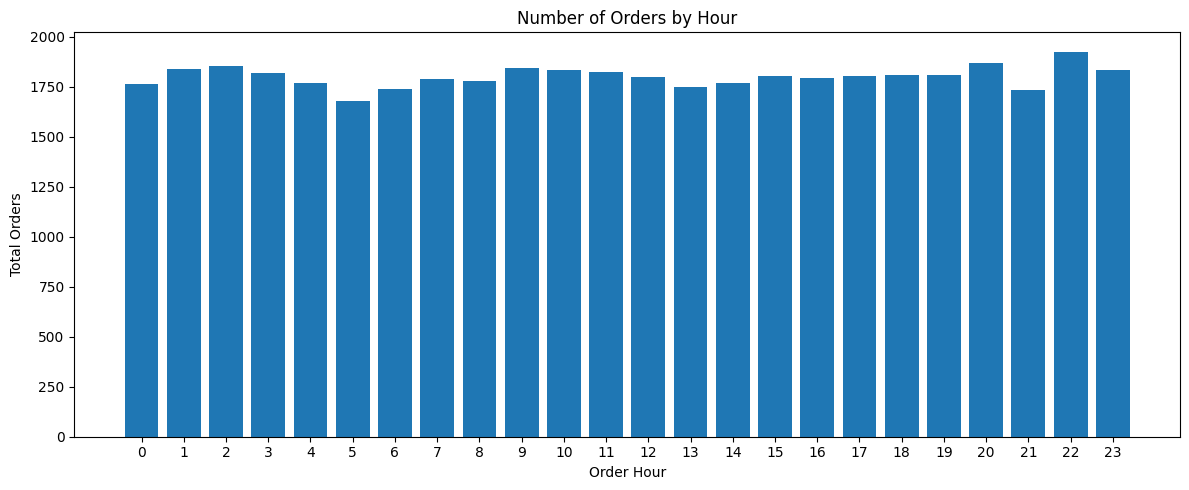

Top 5 Busiest Hours:
    order_hour  total_orders
22          22          1926
20          20          1868
2            2          1852
9            9          1844
1            1          1841


In [ ]:

plt.figure(figsize=(12, 5))

plt.bar(
    hour_analysis["order_hour"],
    hour_analysis["total_orders"]
)

plt.title("Number of Orders by Hour")
plt.xlabel("Order Hour")
plt.ylabel("Total Orders")
plt.xticks(range(24))
plt.tight_layout()
plt.show()

print("Top 5 Busiest Hours:")

print(
    hour_analysis.nlargest(
        5, "total_orders"
    )[["order_hour", "total_orders"]]
)


# New Section

   order_size  total_orders  avg_quantity  avg_delay  avg_delivery_time
0       Small         14930      1.507100   2.096182          31.584193
1      Medium         17076      3.887327   2.007672          31.446767
2       Large          9967      7.282633   1.951239          31.577506
3  Very Large          1255     12.446215   1.803187          31.233466


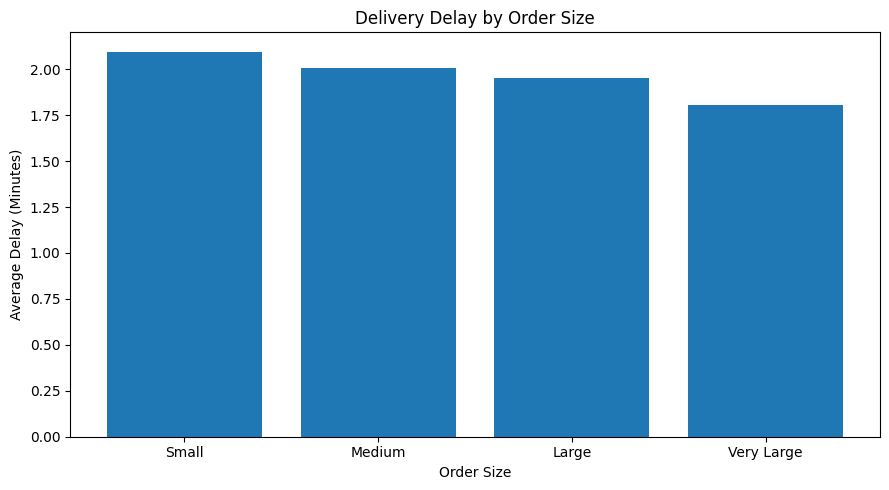

In [ ]:

# DELIVERY DELAY vs ORDER QUANTITY

# Aggregate line items into individual orders
order_level = df.groupby("order_id").agg(
    quantity=("quantity", "sum"),
    promised_eta=("promised_eta_mins", "first"),
    actual_delivery=("actual_delivery_mins", "first"),
    delay=("delay_mins", "first"),
    city=("city", "first"),
    is_on_time=("is_on_time", "first"),
    order_hour=("order_hour", "first")
).reset_index()

# Create order size categories
order_level["order_size"] = pd.cut(
    order_level["quantity"],
    bins=[0, 2, 5, 10, float("inf")],
    labels=["Small", "Medium", "Large", "Very Large"]
)

quantity_analysis = order_level.groupby(
    "order_size", observed=True
).agg(
    total_orders=("order_id", "count"),
    avg_quantity=("quantity", "mean"),
    avg_delay=("delay", "mean"),
    avg_delivery_time=("actual_delivery", "mean")
).reset_index()

print(quantity_analysis)

plt.figure(figsize=(9, 5))

plt.bar(
    quantity_analysis["order_size"].astype(str),
    quantity_analysis["avg_delay"]
)

plt.title("Delivery Delay by Order Size")
plt.xlabel("Order Size")
plt.ylabel("Average Delay (Minutes)")
plt.tight_layout()
plt.show()


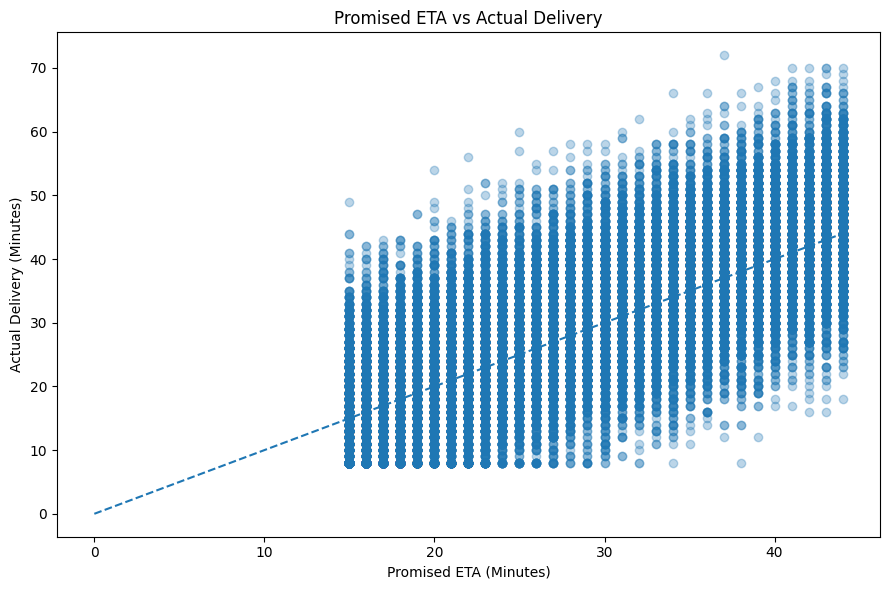

In [ ]:

plt.figure(figsize=(9, 6))

plt.scatter(
    order_level["promised_eta"],
    order_level["actual_delivery"],
    alpha=0.3
)

plt.plot(
    [0, order_level["promised_eta"].max()],
    [0, order_level["promised_eta"].max()],
    linestyle="--"
)

plt.title("Promised ETA vs Actual Delivery")
plt.xlabel("Promised ETA (Minutes)")
plt.ylabel("Actual Delivery (Minutes)")
plt.tight_layout()
plt.show()


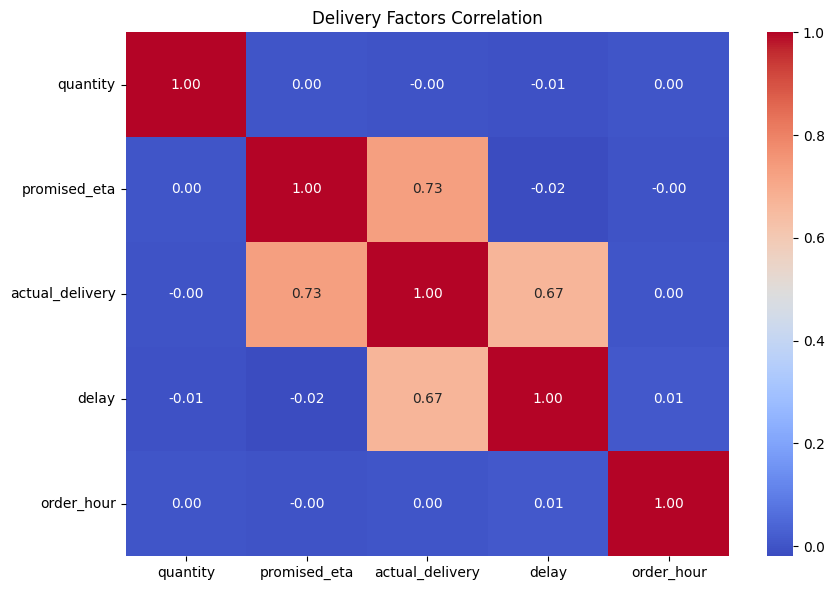

In [ ]:

correlation_data = order_level[
    [
        "quantity",
        "promised_eta",
        "actual_delivery",
        "delay",
        "order_hour"
    ]
].corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_data,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Delivery Factors Correlation")
plt.tight_layout()
plt.show()


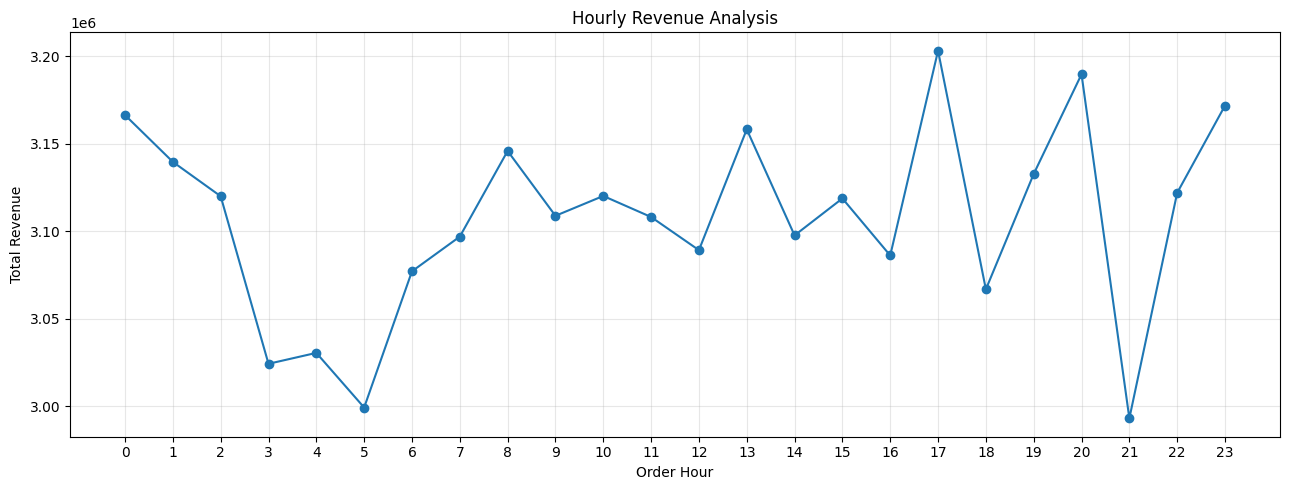

    order_hour     revenue  total_orders
17          17  3203304.06          4057
20          20  3189838.60          4062
23          23  3171929.52          4090
0            0  3166504.19          3938
13          13  3158346.59          3969


In [ ]:

hourly_revenue = df.groupby("order_hour").agg(
    revenue=("line_total", "sum"),
    total_orders=("order_id", "nunique")
).reset_index()

plt.figure(figsize=(13, 5))

plt.plot(
    hourly_revenue["order_hour"],
    hourly_revenue["revenue"],
    marker="o"
)

plt.title("Hourly Revenue Analysis")
plt.xlabel("Order Hour")
plt.ylabel("Total Revenue")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(
    hourly_revenue.sort_values(
        "revenue", ascending=False
    ).head(5)
)


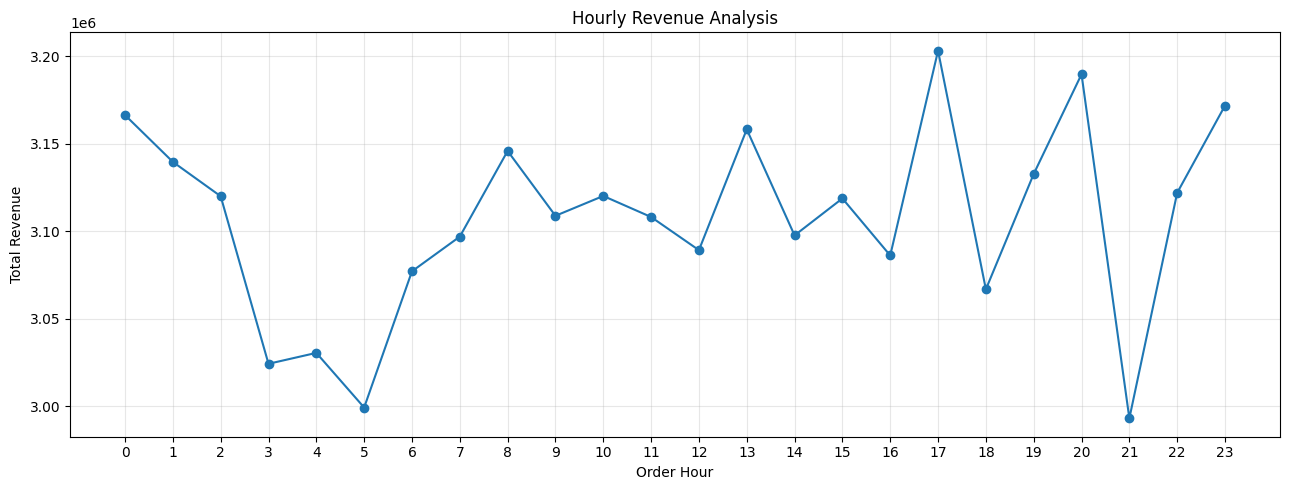

    order_hour     revenue  total_orders
17          17  3203304.06          4057
20          20  3189838.60          4062
23          23  3171929.52          4090
0            0  3166504.19          3938
13          13  3158346.59          3969


In [ ]:

hourly_revenue = df.groupby("order_hour").agg(
    revenue=("line_total", "sum"),
    total_orders=("order_id", "nunique")
).reset_index()

plt.figure(figsize=(13, 5))

plt.plot(
    hourly_revenue["order_hour"],
    hourly_revenue["revenue"],
    marker="o"
)

plt.title("Hourly Revenue Analysis")
plt.xlabel("Order Hour")
plt.ylabel("Total Revenue")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(
    hourly_revenue.sort_values(
        "revenue", ascending=False
    ).head(5)
)


     city  gross_sales  discounts  quantity_sold  discount_percentage
Bengaluru  17801567.34  479041.81          42303             2.620492
  Chennai   8918064.79  241292.77          21270             2.634385
Delhi NCR  13341110.60  359148.08          31593             2.621469
Hyderabad  10498825.88  278972.28          24891             2.588398
   Mumbai  15050901.61  399852.10          35714             2.587913
     Pune   8958542.32  238131.74          21316             2.589325


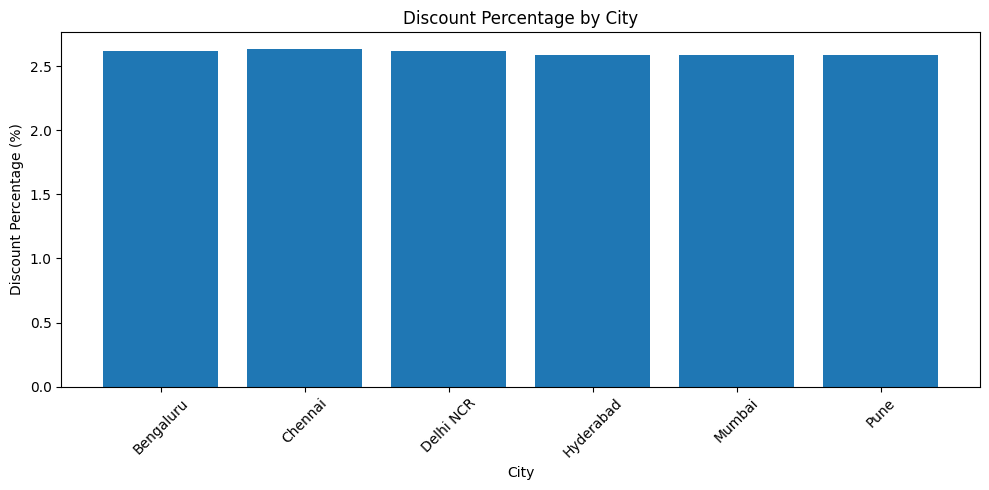

In [ ]:

discount_analysis = df.groupby("city").agg(
    gross_sales=("line_total", "sum"),
    discounts=("discount_amount", "sum"),
    quantity_sold=("quantity", "sum")
).reset_index()

discount_analysis["discount_percentage"] = (
    discount_analysis["discounts"] /
    (discount_analysis["gross_sales"] +
     discount_analysis["discounts"]) * 100
)

print(discount_analysis.to_string(index=False))

plt.figure(figsize=(10, 5))

plt.bar(
    discount_analysis["city"],
    discount_analysis["discount_percentage"]
)

plt.title("Discount Percentage by City")
plt.xlabel("City")
plt.ylabel("Discount Percentage (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [ ]:

# BUSINESS PERFORMANCE REPORT

total_revenue = df["line_total"].sum()
total_discount = df["discount_amount"].sum()
total_orders = df["order_id"].nunique()
total_items = df["quantity"].sum()

print("=" * 45)
print("FOOD & GROCERY BUSINESS REPORT")
print("=" * 45)

print("Total Revenue:", round(total_revenue, 2))
print("Total Orders:", total_orders)
print("Total Items Sold:", total_items)
print("Total Discounts:", round(total_discount, 2))

print(
    "Average Order Value:",
    round(total_revenue / total_orders, 2)
)

print(
    "Average Items per Order:",
    round(total_items / total_orders, 2)
)

print("=" * 45)


FOOD & GROCERY BUSINESS REPORT
Total Revenue: 74569012.54
Total Orders: 43228
Total Items Sold: 177087
Total Discounts: 1996438.78
Average Order Value: 1725.02
Average Items per Order: 4.1


In [ ]:

# STEP 1: MACHINE LEARNING DATA PREPARATION

import pandas as pd
import numpy as np

# Aggregate line items into individual orders
ml_df = df.groupby("order_id").agg(
    city=("city", "first"),
    order_hour=("order_hour", "first"),
    order_day=("order_day", "first"),
    total_quantity=("quantity", "sum"),
    total_order_value=("line_total", "sum"),
    total_discount=("discount_amount", "sum"),
    promised_eta=("promised_eta_mins", "first"),
    is_on_time=("is_on_time", "first")
).reset_index()

# Create target: 1 = Late, 0 = On Time
print("is_on_time values:")
print(ml_df["is_on_time"].value_counts(dropna=False))

# Convert common Boolean/numeric values
if pd.api.types.is_bool_dtype(ml_df["is_on_time"]):
    ml_df["late_delivery"] = (
        ~ml_df["is_on_time"]
    ).astype(int)

elif pd.api.types.is_numeric_dtype(ml_df["is_on_time"]):
    ml_df["late_delivery"] = (
        1 - ml_df["is_on_time"].astype(int)
    )

else:
    status = ml_df["is_on_time"].astype(str).str.lower().str.strip()

    mapping = {
        "true": 0,
        "false": 1,
        "1": 0,
        "0": 1,
        "yes": 0,
        "no": 1
    }

    ml_df["late_delivery"] = status.map(mapping)

# Check target
print("\nMachine Learning Dataset:")
print("Shape:", ml_df.shape)
print(ml_df.head())

print("\nTarget Distribution:")
print(ml_df["late_delivery"].value_counts(dropna=False))


is_on_time values:
is_on_time
0    24748
1    18480
Name: count, dtype: int64

Machine Learning Dataset:
Shape: (43228, 10)
      order_id       city  order_hour  order_day  total_quantity  \
0  ORD_0000002  Delhi NCR           9    Tuesday               4   
1  ORD_0000003     Mumbai          14   Thursday               1   
2  ORD_0000004    Chennai          21     Sunday               1   
3  ORD_0000005       Pune          18  Wednesday               3   
4  ORD_0000006       Pune           8  Wednesday               5   

   total_order_value  total_discount  promised_eta  is_on_time  late_delivery  
0            2326.47            3.41            28           0              1  
1             429.70           12.06            16           0              1  
2             236.28           62.11            20           0              1  
3            1855.62           14.35            31           0              1  
4             804.52           24.48            39           0     

In [ ]:

print("Missing Values:")
print(ml_df.isnull().sum())

print("\nTarget Distribution (%):")
print(
    ml_df["late_delivery"]
    .value_counts(normalize=True) * 100
)

print("\nDataset Information:")
ml_df.info()


Missing Values:
order_id             0
city                 0
order_hour           0
order_day            0
total_quantity       0
total_order_value    0
total_discount       0
promised_eta         0
is_on_time           0
late_delivery        0
dtype: int64

Target Distribution (%):
late_delivery
1    57.249931
0    42.750069
Name: proportion, dtype: float64

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 43228 entries, 0 to 43227
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   order_id           43228 non-null  object 
 1   city               43228 non-null  object 
 2   order_hour         43228 non-null  int32  
 3   order_day          43228 non-null  object 
 4   total_quantity     43228 non-null  int64  
 5   total_order_value  43228 non-null  float64
 6   total_discount     43228 non-null  float64
 7   promised_eta       43228 non-null  int64  
 8   is_on_time         432

In [ ]:

!pip install -q xgboost


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score
)

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Input features available when the order is placed
features = [
    "city",
    "order_hour",
    "order_day",
    "total_quantity",
    "total_order_value",
    "total_discount",
    "promised_eta"
]

X = ml_df[features]
y = ml_df["late_delivery"]

# Categorical and numerical columns
categorical_features = ["city", "order_day"]

numeric_features = [
    "order_hour",
    "total_quantity",
    "total_order_value",
    "total_discount",
    "promised_eta"
]

# Encode categorical variables
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_features),
        ("num", "passthrough", numeric_features)
    ]
)

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))


Training records: 34582
Testing records: 8646

Training target distribution:
late_delivery
1    0.572494
0    0.427506
Name: proportion, dtype: float64


In [ ]:

models = {
    "Decision Tree": DecisionTreeClassifier(
        max_depth=8,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=200,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )
}

trained_models = {}
results = []

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    print(f"\nTraining {name}...")

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)
    probabilities = pipeline.predict_proba(X_test)[:, 1]

    trained_models[name] = pipeline

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions),
        "ROC AUC": roc_auc_score(y_test, probabilities)
    })

    print(f"{name} training completed!")

results_df = pd.DataFrame(results)

print("\nMODEL COMPARISON")
print(results_df.round(4).to_string(index=False))



Training Decision Tree...
Decision Tree training completed!

Training Random Forest...
Random Forest training completed!

Training XGBoost...
XGBoost training completed!

MODEL COMPARISON
        Model  Accuracy  Precision  Recall  F1 Score  ROC AUC
Decision Tree    0.5294     0.5690  0.7341    0.6411   0.4912
Random Forest    0.5036     0.5637  0.5879    0.5756   0.4937
      XGBoost    0.5689     0.5731  0.9685    0.7201   0.4958


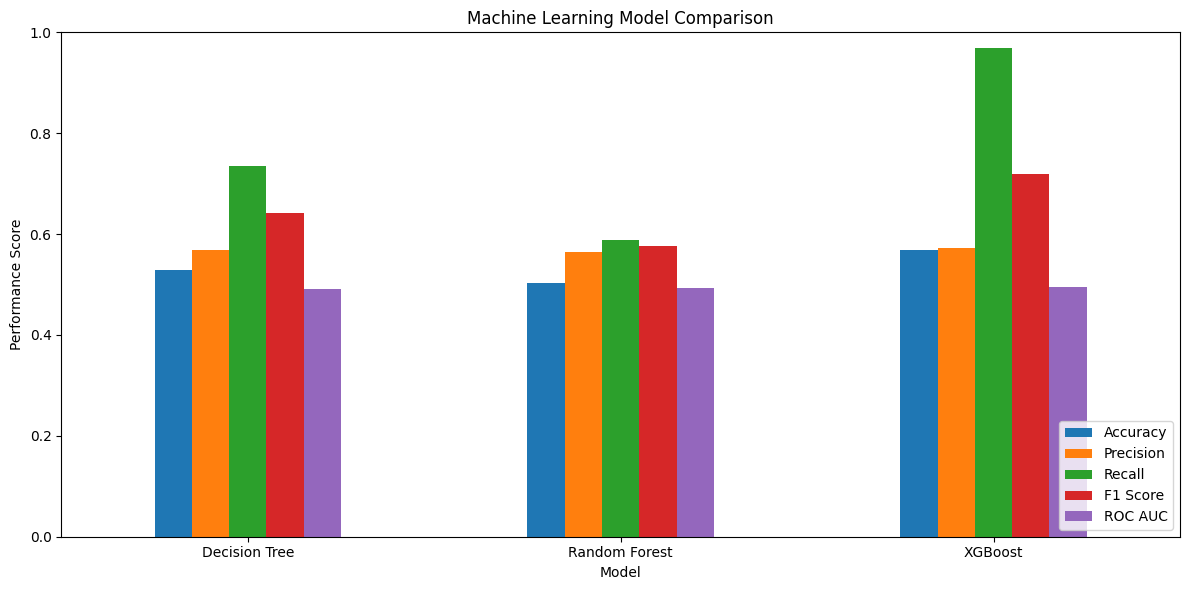

In [ ]:

results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score", "ROC AUC"]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Machine Learning Model Comparison")
plt.ylabel("Performance Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


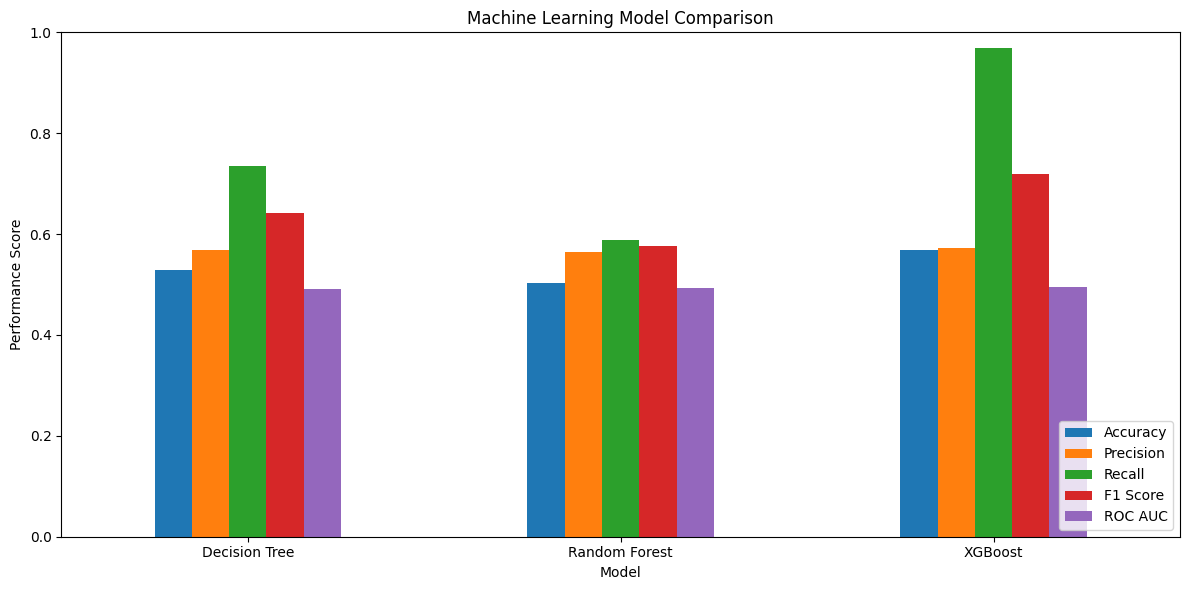

In [ ]:

results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score", "ROC AUC"]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Machine Learning Model Comparison")
plt.ylabel("Performance Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


Best Model: XGBoost

Classification Report:
              precision    recall  f1-score   support

           0       0.44      0.03      0.06      3696
           1       0.57      0.97      0.72      4950

    accuracy                           0.57      8646
   macro avg       0.51      0.50      0.39      8646
weighted avg       0.52      0.57      0.44      8646



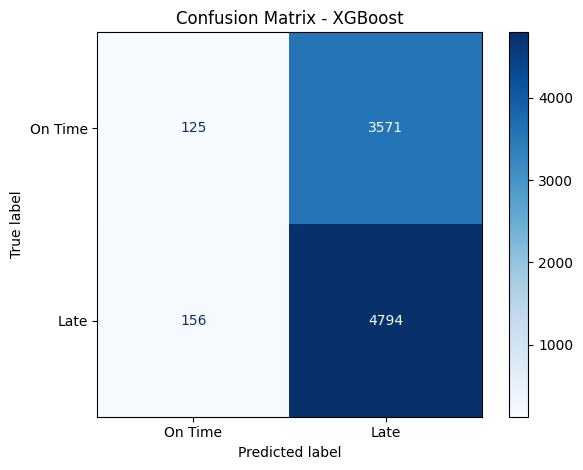

In [ ]:

best_model_name = results_df.loc[
    results_df["F1 Score"].idxmax(),
    "Model"
]

best_model = trained_models[best_model_name]

predictions = best_model.predict(X_test)

print("Best Model:", best_model_name)

print("\nClassification Report:")
print(classification_report(y_test, predictions))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions,
    display_labels=["On Time", "Late"],
    cmap="Blues"
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.show()


In [ ]:

# COMPARE PREDICTIONS FROM ALL MODELS

from sklearn.metrics import confusion_matrix

for name, model in trained_models.items():

    pred = model.predict(X_test)

    print("\n", "=" * 45)
    print("MODEL:", name)

    print("Actual distribution:")
    print(y_test.value_counts().to_dict())

    print("Predicted distribution:")
    print(pd.Series(pred).value_counts().to_dict())

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, pred))

    print("\nClassification Report:")
    print(classification_report(y_test, pred))



MODEL: Decision Tree
Actual distribution:
{1: 4950, 0: 3696}
Predicted distribution:
{1: 6387, 0: 2259}

Confusion Matrix:
[[ 943 2753]
 [1316 3634]]

Classification Report:
              precision    recall  f1-score   support

           0       0.42      0.26      0.32      3696
           1       0.57      0.73      0.64      4950

    accuracy                           0.53      8646
   macro avg       0.49      0.49      0.48      8646
weighted avg       0.50      0.53      0.50      8646


MODEL: Random Forest
Actual distribution:
{1: 4950, 0: 3696}
Predicted distribution:
{1: 5162, 0: 3484}

Confusion Matrix:
[[1444 2252]
 [2040 2910]]

Classification Report:
              precision    recall  f1-score   support

           0       0.41      0.39      0.40      3696
           1       0.56      0.59      0.58      4950

    accuracy                           0.50      8646
   macro avg       0.49      0.49      0.49      8646
weighted avg       0.50      0.50      0.50      86

                 Feature  Importance
     num__total_discount    0.241692
  num__total_order_value    0.237582
       num__promised_eta    0.146730
         num__order_hour    0.140501
     num__total_quantity    0.093905
     cat__city_Bengaluru    0.012139
   cat__order_day_Monday    0.011463
        cat__city_Mumbai    0.011346
     cat__city_Delhi NCR    0.011182
 cat__order_day_Saturday    0.011104
  cat__order_day_Tuesday    0.010918
   cat__order_day_Sunday    0.010554
cat__order_day_Wednesday    0.010421
   cat__order_day_Friday    0.010329
          cat__city_Pune    0.010114
     cat__city_Hyderabad    0.010087
 cat__order_day_Thursday    0.010054
       cat__city_Chennai    0.009880


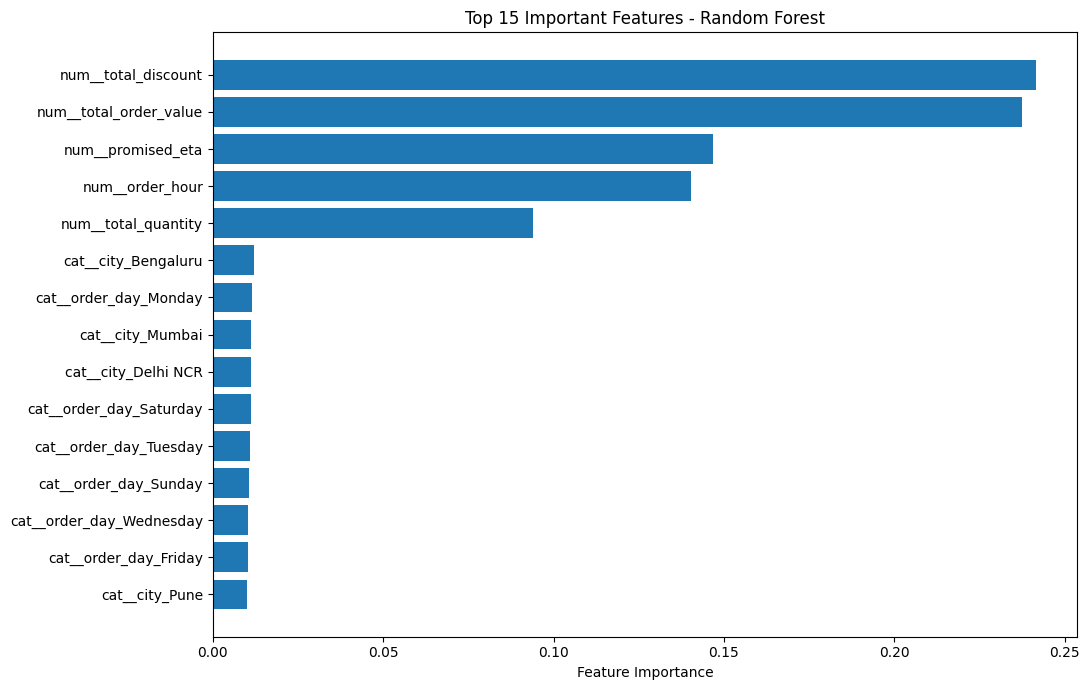

In [ ]:

# FEATURE IMPORTANCE - RANDOM FOREST

rf_model = trained_models["Random Forest"]

rf_classifier = rf_model.named_steps["model"]

feature_names = (
    rf_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_classifier.feature_importances_
})

importance_df = importance_df.sort_values(
    "Importance", ascending=False
)

print(importance_df.to_string(index=False))

# Visualization
plt.figure(figsize=(11, 7))

top_features = importance_df.head(15)

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.title("Top 15 Important Features - Random Forest")
plt.xlabel("Feature Importance")
plt.tight_layout()
plt.show()


In [ ]:

from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, recall_score

baseline = DummyClassifier(strategy="most_frequent")

baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_test)

print("BASELINE MODEL RESULTS")

print(
    "Accuracy:",
    accuracy_score(y_test, baseline_predictions)
)

print(
    "Late Delivery F1:",
    f1_score(y_test, baseline_predictions)
)

print(
    "Late Delivery Recall:",
    recall_score(y_test, baseline_predictions)
)


BASELINE MODEL RESULTS
Accuracy: 0.5725190839694656
Late Delivery F1: 0.7281553398058253
Late Delivery Recall: 1.0


In [ ]:

# CHECK FEATURE RELATIONSHIPS

print("FEATURE SUMMARY")

print(
    ml_df[
        [
            "order_hour",
            "total_quantity",
            "total_order_value",
            "total_discount",
            "promised_eta"
        ]
    ].describe().round(2)
)

print("\nAverage values by delivery status:")

print(
    ml_df.groupby("late_delivery")[
        [
            "order_hour",
            "total_quantity",
            "total_order_value",
            "total_discount",
            "promised_eta"
        ]
    ].mean().round(2)
)


FEATURE SUMMARY
       order_hour  total_quantity  total_order_value  total_discount  \
count    43228.00        43228.00           43228.00        43228.00   
mean        11.55            4.10            1725.02           46.18   
std          6.94            2.74            1384.05           39.38   
min          0.00            1.00               0.00            0.00   
25%          6.00            2.00             683.00           16.27   
50%         12.00            4.00            1378.48           36.39   
75%         18.00            6.00            2405.76           65.18   
max         23.00           23.00           10847.38          363.48   

       promised_eta  
count      43228.00  
mean          29.50  
std            8.65  
min           15.00  
25%           22.00  
50%           30.00  
75%           37.00  
max           44.00  

Average values by delivery status:
               order_hour  total_quantity  total_order_value  total_discount  \
late_delivery        

In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score
)

comparison = []

for name, model in trained_models.items():

    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]

    comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1 Score": f1_score(y_test, pred),
        "Balanced Accuracy": balanced_accuracy_score(y_test, pred),
        "ROC AUC": roc_auc_score(y_test, prob)
    })

# Majority-class baseline
from sklearn.dummy import DummyClassifier

dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)

dummy_pred = dummy.predict(X_test)

comparison.append({
    "Model": "Baseline",
    "Accuracy": accuracy_score(y_test, dummy_pred),
    "Precision": precision_score(y_test, dummy_pred),
    "Recall": recall_score(y_test, dummy_pred),
    "F1 Score": f1_score(y_test, dummy_pred),
    "Balanced Accuracy": balanced_accuracy_score(y_test, dummy_pred),
    "ROC AUC": 0.5
})

comparison_df = pd.DataFrame(comparison)

print(comparison_df.round(4).to_string(index=False))


        Model  Accuracy  Precision  Recall  F1 Score  Balanced Accuracy  ROC AUC
Decision Tree    0.5294     0.5690  0.7341    0.6411             0.4946   0.4912
Random Forest    0.5036     0.5637  0.5879    0.5756             0.4893   0.4937
      XGBoost    0.5689     0.5731  0.9685    0.7201             0.5012   0.4958
     Baseline    0.5725     0.5725  1.0000    0.7282             0.5000   0.5000


In [ ]:

from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

param_grid = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [5, 8, 12, 16, None],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [2, 5, 10],
    "model__class_weight": [None, "balanced"]
}

random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_grid,
    n_iter=15,
    scoring="f1_macro",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

best_rf = random_search.best_estimator_

print("Best Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation Macro F1:")
print(random_search.best_score_)


Fitting 3 folds for each of 15 candidates, totalling 45 fits
Best Parameters:
{'model__n_estimators': 300, 'model__min_samples_split': 2, 'model__min_samples_leaf': 10, 'model__max_depth': 12, 'model__class_weight': 'balanced'}

Best Cross-Validation Macro F1:
0.5002794924921583


OPTIMIZED RANDOM FOREST
              precision    recall  f1-score   support

     On Time       0.43      0.41      0.42      3696
        Late       0.57      0.59      0.58      4950

    accuracy                           0.51      8646
   macro avg       0.50      0.50      0.50      8646
weighted avg       0.51      0.51      0.51      8646



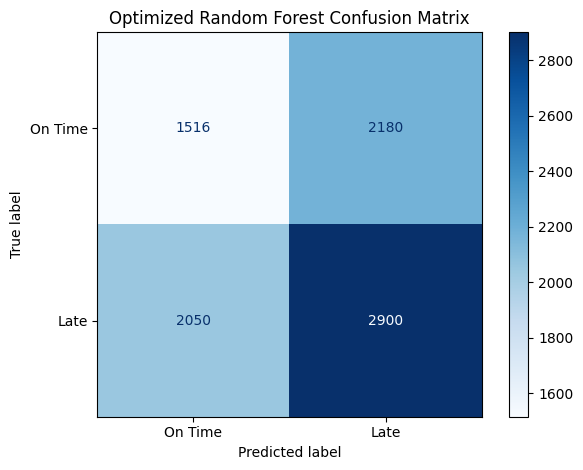

In [ ]:

from sklearn.metrics import classification_report
from sklearn.metrics import ConfusionMatrixDisplay

optimized_predictions = best_rf.predict(X_test)

print("OPTIMIZED RANDOM FOREST")

print(
    classification_report(
        y_test,
        optimized_predictions,
        target_names=["On Time", "Late"]
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    optimized_predictions,
    display_labels=["On Time", "Late"],
    cmap="Blues"
)

plt.title("Optimized Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()


In [ ]:

import joblib

joblib.dump(
    best_rf,
    "food_delivery_random_forest.pkl"
)

print("Model saved successfully!")


Model saved successfully!


In [ ]:

!pip install -q shap


In [ ]:

from sklearn.inspection import permutation_importance

# Use optimized Random Forest
importance_result = permutation_importance(
    best_rf,
    X_test,
    y_test,
    scoring="f1_macro",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance_result.importances_mean,
    "Std": importance_result.importances_std
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)

print("FEATURE IMPORTANCE")
print(importance_df.to_string(index=False))


FEATURE IMPORTANCE
          Feature  Importance      Std
total_order_value    0.004886 0.002165
       order_hour   -0.000322 0.002555
   total_quantity   -0.001143 0.002700
     promised_eta   -0.001229 0.003272
             city   -0.003498 0.003864
        order_day   -0.004931 0.004839
   total_discount   -0.005254 0.003449


In [ ]:


!pip install -q shap



In [ ]:
import joblib
import os
from sklearn.inspection import permutation_importance

# Fallback: Try to use the model in memory or load it from disk
try:
    model_to_use = best_rf
    print("Using 'best_rf' directly from active memory.")
except NameError:
    print("Variable 'best_rf' not found in memory. Attempting to load from disk...")
    pkl_path = "food_delivery_random_forest.pkl"
    if os.path.exists(pkl_path):
        model_to_use = joblib.load(pkl_path)
        print("Successfully loaded model from disk file.")
    else:
        raise FileNotFoundError(
            "\n[ERROR] Could not find the model in memory OR on disk.\n"
            "Your Colab session likely restarted and wiped both your variables and local files.\n"
            "Please re-run the notebook cells from the top to re-train and save the model!"
        )

# Use optimized Random Forest to perform Permutation Importance
importance_result = permutation_importance(
    model_to_use,
    X_test,
    y_test,
    scoring="f1_macro",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance_result.importances_mean,
    "Std": importance_result.importances_std
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)

print("\nFEATURE IMPORTANCE")
print(importance_df.to_string(index=False))

Using 'best_rf' directly from active memory.

FEATURE IMPORTANCE
          Feature  Importance      Std
total_order_value    0.004886 0.002165
       order_hour   -0.000322 0.002555
   total_quantity   -0.001143 0.002700
     promised_eta   -0.001229 0.003272
             city   -0.003498 0.003864
        order_day   -0.004931 0.004839
   total_discount   -0.005254 0.003449


In [ ]:

!pip install -q shap


In [ ]:
import sklearn
import joblib
import sys

print("Scikit-learn:", sklearn.__version__)
print("Joblib:", joblib.__version__)
print("Python:", sys.version)

Scikit-learn: 1.6.1
Joblib: 1.6.0
Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]


In [ ]:

from sklearn.inspection import permutation_importance

# Use optimized Random Forest
importance_result = permutation_importance(
    best_rf,
    X_test,
    y_test,
    scoring="f1_macro",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance_result.importances_mean,
    "Std": importance_result.importances_std
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)

print("FEATURE IMPORTANCE")
print(importance_df.to_string(index=False))


FEATURE IMPORTANCE
          Feature  Importance      Std
total_order_value    0.004886 0.002165
       order_hour   -0.000322 0.002555
   total_quantity   -0.001143 0.002700
     promised_eta   -0.001229 0.003272
             city   -0.003498 0.003864
        order_day   -0.004931 0.004839
   total_discount   -0.005254 0.003449


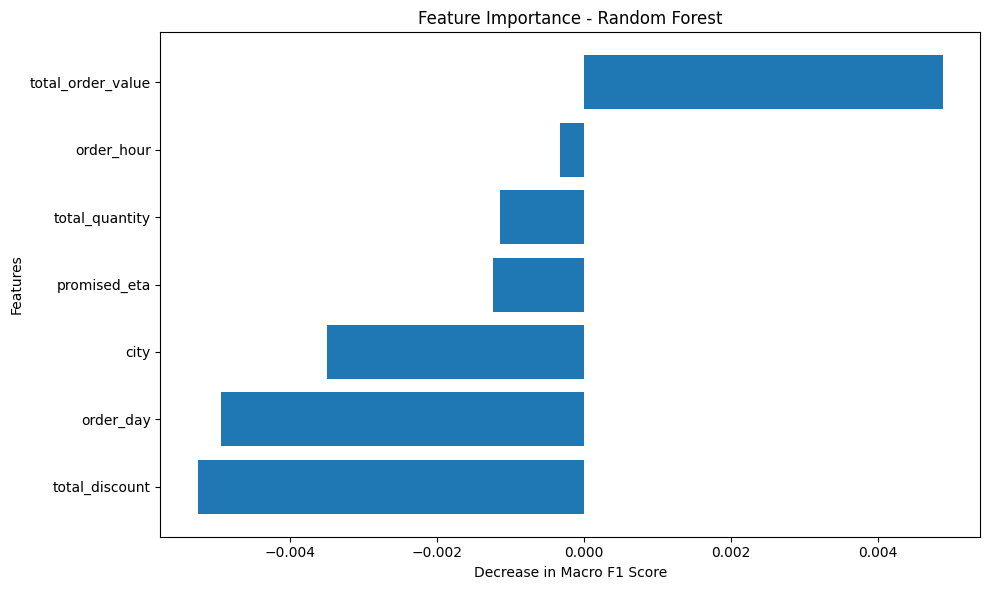

In [ ]:

plt.figure(figsize=(10, 6))

plt.barh(
    importance_df["Feature"][::-1],
    importance_df["Importance"][::-1]
)

plt.title("Feature Importance - Random Forest")
plt.xlabel("Decrease in Macro F1 Score")
plt.ylabel("Features")

plt.tight_layout()
plt.show()


In [ ]:

import shap

# Transform test data using trained preprocessing pipeline
X_test_transformed = (
    best_rf.named_steps["preprocessor"]
    .transform(X_test)
)

feature_names = (
    best_rf.named_steps["preprocessor"]
    .get_feature_names_out()
)

# Explain the Random Forest
explainer = shap.TreeExplainer(
    best_rf.named_steps["model"]
)

# Use a sample to reduce computation
sample_size = min(500, X_test_transformed.shape[0])

shap_values = explainer.shap_values(
    X_test_transformed[:sample_size]
)

print("SHAP analysis completed!")


SHAP analysis completed!


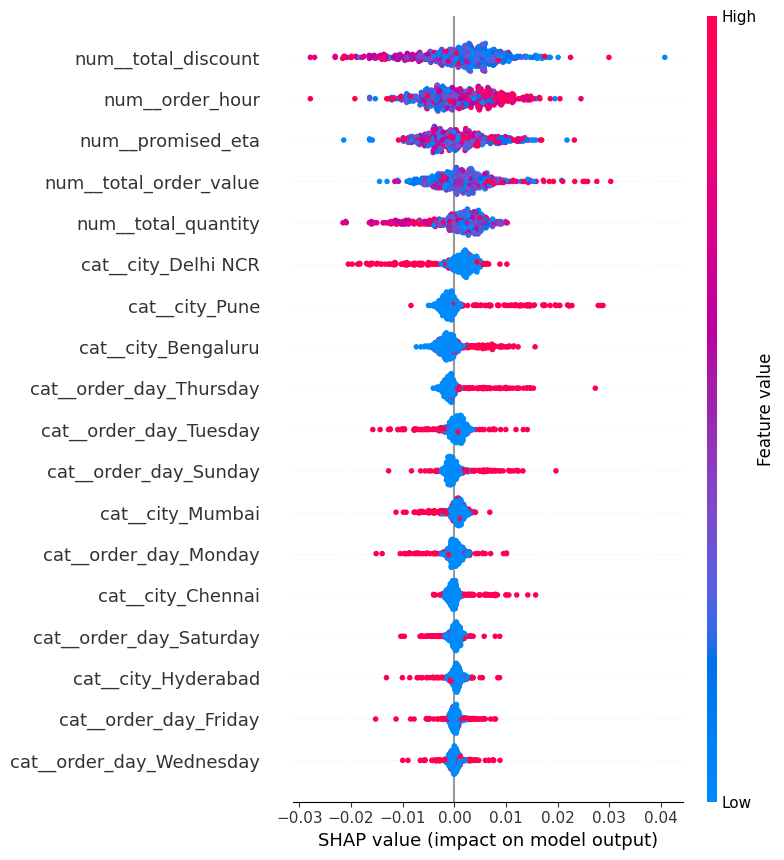

In [ ]:

# Extract SHAP values for late-delivery class
if isinstance(shap_values, list):
    late_shap = shap_values[1]
elif shap_values.ndim == 3:
    late_shap = shap_values[:, :, 1]
else:
    late_shap = shap_values

shap.summary_plot(
    late_shap,
    X_test_transformed[:sample_size],
    feature_names=feature_names,
    show=True
)


In [ ]:

import joblib
import os

# Save optimized model
joblib.dump(
    best_rf,
    "food_delivery_random_forest.pkl"
)

print("Model saved successfully!")


Model saved successfully!


In [ ]:

%%writefile app.py

import streamlit as st
import pandas as pd
import joblib

# Load trained model
model = joblib.load("food_delivery_random_forest.pkl")

st.set_page_config(
    page_title="Food Delivery Intelligence",
    page_icon="🚚",
    layout="wide"
)

st.title("🚚 Food & Grocery Delivery Intelligence")
st.subheader("AI-Powered Delivery Delay Prediction")

st.write(
    "Enter order details to predict the delivery status."
)

# Sidebar
st.sidebar.header("Order Information")

city = st.sidebar.selectbox(
    "Select City",
    ["Bengaluru", "Pune", "Chennai",
     "Mumbai", "Delhi NCR", "Hyderabad"]
)

order_hour = st.sidebar.slider(
    "Order Hour",
    0, 23, 13
)

order_day = st.sidebar.selectbox(
    "Order Day",
    ["Monday", "Tuesday", "Wednesday",
     "Thursday", "Friday", "Saturday", "Sunday"]
)

quantity = st.sidebar.number_input(
    "Total Quantity",
    min_value=1,
    value=3
)

order_value = st.sidebar.number_input(
    "Total Order Value",
    min_value=0.0,
    value=500.0
)

discount = st.sidebar.number_input(
    "Total Discount",
    min_value=0.0,
    value=20.0
)

promised_eta = st.sidebar.number_input(
    "Promised ETA (Minutes)",
    min_value=1,
    value=40
)

if st.button("Predict Delivery Status"):

    input_data = pd.DataFrame([{
        "city": city,
        "order_hour": order_hour,
        "order_day": order_day,
        "total_quantity": quantity,
        "total_order_value": order_value,
        "total_discount": discount,
        "promised_eta": promised_eta
    }])

    prediction = int(model.predict(input_data)[0])

    probabilities = model.predict_proba(input_data)[0]

    late_probability = probabilities[1] * 100

    st.divider()

    st.subheader("Prediction Results")

    col1, col2 = st.columns(2)

    with col1:
        if prediction == 1:
            st.error("⚠️ Late Delivery Predicted")
        else:
            st.success("✅ On-Time Delivery Predicted")

    with col2:
        st.metric(
            "Predicted Late Delivery Probability",
            f"{late_probability:.2f}%"
        )

    st.progress(float(probabilities[1]))

    st.caption(
        "This is a model prediction, not a guaranteed delivery outcome."
    )

st.divider()

st.subheader("About This Project")

st.write("""
This application uses a trained Random Forest classification
pipeline to predict food and grocery delivery delays.

Technologies:
- Python
- Pandas
- Scikit-learn
- Random Forest
- Streamlit
""")


Overwriting app.py


In [ ]:

from google.colab import files

files.download("app.py")

files.download("food_delivery_random_forest.pkl")



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import sys
import sklearn
import joblib

print("Python:", sys.executable)
print("Python version:", sys.version)
print("Scikit-learn:", sklearn.__version__)
print("Joblib:", joblib.__version__)

Python: /usr/bin/python3
Python version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Scikit-learn: 1.6.1
Joblib: 1.6.0


In [ ]:
import sklearn, joblib
print("sklearn:", sklearn.__version__, "| joblib:", joblib.__version__)

sklearn: 1.6.1 | joblib: 1.6.0


In [ ]:
from pathlib import Path

# In interactive environments like Colab, use the current working directory instead of __file__
BASE_DIR = Path.cwd()
MODEL_PATH = BASE_DIR / "food_delivery_random_forest.pkl"

print("Resolved Model Path:", MODEL_PATH)

Resolved Model Path: /content/food_delivery_random_forest.pkl


In [ ]:
import os

os.makedirs("reports", exist_ok=True)

# Example: save the active matplotlib figure before plt.show()
plt.tight_layout()
plt.savefig("reports/late_delivery_rate_by_city.png", dpi=300, bbox_inches="tight")
plt.show()

<Figure size 640x480 with 0 Axes>

In [ ]:
from pathlib import Path
import joblib

# Safely fall back to the current working directory in interactive notebook environments
try:
    BASE_DIR = Path(__file__).resolve().parent.parent
except NameError:
    BASE_DIR = Path.cwd()

MODEL_PATH = BASE_DIR / "food_delivery_random_forest.pkl"
model = joblib.load(MODEL_PATH)
print("Successfully loaded model from:", MODEL_PATH)

Successfully loaded model from: /content/food_delivery_random_forest.pkl
